# 06 · Clustering de los scores del MFPCA

**Fase del plan:** F6 – Clustering de los scores.

**Objetivo:** agrupar los 200 países según la forma conjunta de sus trayectorias de TFR, LEx y CNMR_t (1950–2023), representadas por los scores $\hat{\boldsymbol\rho}_i=(\hat\rho_{i1},\dots,\hat\rho_{iL})$ del MFPCA. El método principal es un modelo de mezcla gaussiana (GMM, `mclust`) con $G$ elegido por BIC; Ward y k-means sirven de contraste. Se evalúan el número de grupos, la concordancia entre métodos y la estabilidad por bootstrap.

**Solución principal:** las $L=9$ componentes retenidas en F5. **Comparación** (acordada tras F5): solo las componentes interpretables $\rho_1$–$\rho_4$ (81.6 % de la varianza). El corte en 4 es el natural porque:
- hay un salto claro entre $\hat\nu_4$ y $\hat\nu_5$ (razón 0.44);
- el par (5, 6) está cuasi-degenerado, así que no se puede quedar con $\rho_5$ sin $\rho_6$;
- $\rho_6$, $\rho_7$ y $\rho_9$ son episodios migratorios cortos.

**Entradas:** `output/data/mfpca_nucleo_1950_2023.rds`, `output/data/config.rds`.

**Salidas:** `output/data/clusters_principal.rds`, `output/data/funciones_clustering.rds`, tablas `output/tables/cluster_*` y figuras `cl_*`.


## Configuración
Los scores se usan **sin reescalar**. Cada $\hat\rho_r$ tiene varianza $\hat\nu_r$, así que la distancia euclídea entre vectores de scores aproxima la distancia $L^2$ entre las trayectorias normalizadas (identidad de Parseval). Estandarizar cada score daría a $\rho_9$ (1.2 % de la varianza) el mismo peso que a $\rho_1$ (54.8 %).


In [1]:
suppressPackageStartupMessages({
  library(mclust)       # mclust define map(): se carga antes que tidyverse
  library(cluster)
  library(fpc)
  library(factoextra)
  library(tidyverse)
  library(patchwork)
  library(here)
})
cfg <- readRDS(here::here("output/data/config.rds")); invisible(list2env(cfg, envir = globalenv())); set.seed(SEED)
options(repr.plot.width = 12, repr.plot.height = 7, repr.plot.res = 120, width = 150)
stopifnot(identical(select, dplyr::select), identical(map, purrr::map))

res_mfpca <- readRDS(here::here("output/data/mfpca_nucleo_1950_2023.rds"))
L <- res_mfpca$L
info   <- res_mfpca$scores |> select(ISO3_code, Location, region)
scores <- as.matrix(res_mfpca$scores[, paste0("rho", 1:L)]); rownames(scores) <- info$ISO3_code
scores4 <- scores[, 1:4]
stopifnot(L == 9, nrow(scores) == 200, !anyNA(scores))

CAPTION <- "Fuente: UN WPP 2024"
OKABE <- c("#E69F00", "#56B4E9", "#009E73", "#F0E442", "#0072B2", "#D55E00", "#CC79A7", "#000000")
cat("L =", L, "| países:", nrow(scores), "| G_RANGO:", G_RANGO, "| B_BOOT:", B_BOOT, "\n")
print(round(apply(scores, 2, var), 2))


L = 9 | países: 200 | G_RANGO: 2 3 4 5 6 7 8 | B_BOOT: 500 


  rho1   rho2   rho3   rho4   rho5   rho6   rho7   rho8   rho9 
120.09  32.05  14.12  12.42   5.48   5.08   3.94   3.22   2.69 


## 1. Modelo de mezcla gaussiana y criterio BIC

Se supone que los scores provienen de una mezcla de $G$ normales $L$-variadas:
$$
f(\hat{\boldsymbol\rho}_i)=\sum_{g=1}^{G}\pi_g\,\phi_L\big(\hat{\boldsymbol\rho}_i;\boldsymbol\mu_g,\boldsymbol\Sigma_g\big),\qquad \pi_g>0,\ \sum_g\pi_g=1 .
$$
`mclust` parametriza las covarianzas con la descomposición espectral $\boldsymbol\Sigma_g=\lambda_g\mathbf D_g\mathbf A_g\mathbf D_g^\top$:
- $\lambda_g$ es el **volumen**;
- $\mathbf A_g$ (diagonal, $|\mathbf A_g|=1$) es la **forma**;
- $\mathbf D_g$ es la **orientación**.

Cada uno puede ser igual (E) o variable (V) entre grupos, o tomar la forma identidad o diagonal (I). Así surgen los 14 modelos (EII, VII, EEI, …, VVV). Los parámetros se estiman por máxima verosimilitud con el algoritmo EM, inicializado con clustering jerárquico basado en el modelo.

**Criterio BIC (convención de `mclust`, mayor es mejor):**
$$
\mathrm{BIC}(\mathcal M,G)=2\,\ell(\hat{\boldsymbol\theta};\mathcal M,G)-d_{\mathcal M,G}\log n ,
$$
donde $\ell$ es la log-verosimilitud maximizada y $d$ el número de parámetros libres. Se elige el par (modelo, $G$) con mayor BIC, con $G\in\{2,\dots,8\}$.

**Clasificación e incertidumbre.** Cada país se asigna al grupo con mayor probabilidad posterior,
$$
\hat z_{ig}=\frac{\hat\pi_g\phi_L(\hat{\boldsymbol\rho}_i;\hat{\boldsymbol\mu}_g,\hat{\boldsymbol\Sigma}_g)}{\sum_h\hat\pi_h\phi_L(\hat{\boldsymbol\rho}_i;\hat{\boldsymbol\mu}_h,\hat{\boldsymbol\Sigma}_h)},\qquad \text{incertidumbre}_i=1-\max_g\hat z_{ig}.
$$


## 2. GMM (`mclust`)


Best BIC values:
             VEI,5       VEI,6       VEI,4       VEI,7       VEI,8
BIC      -9092.885 -9106.88979 -9113.57754 -9123.28201 -9129.33866
BIC diff     0.000   -14.00525   -20.69301   -30.39748   -36.45413



Ganador por BIC: modelo VEI con G = 5 (BIC = -9092.9)


grupo
 1  2  3  4  5 
44 72 23 42 19 


Modelos sin ajuste (BIC = NA) en alguna G: 0 celdas


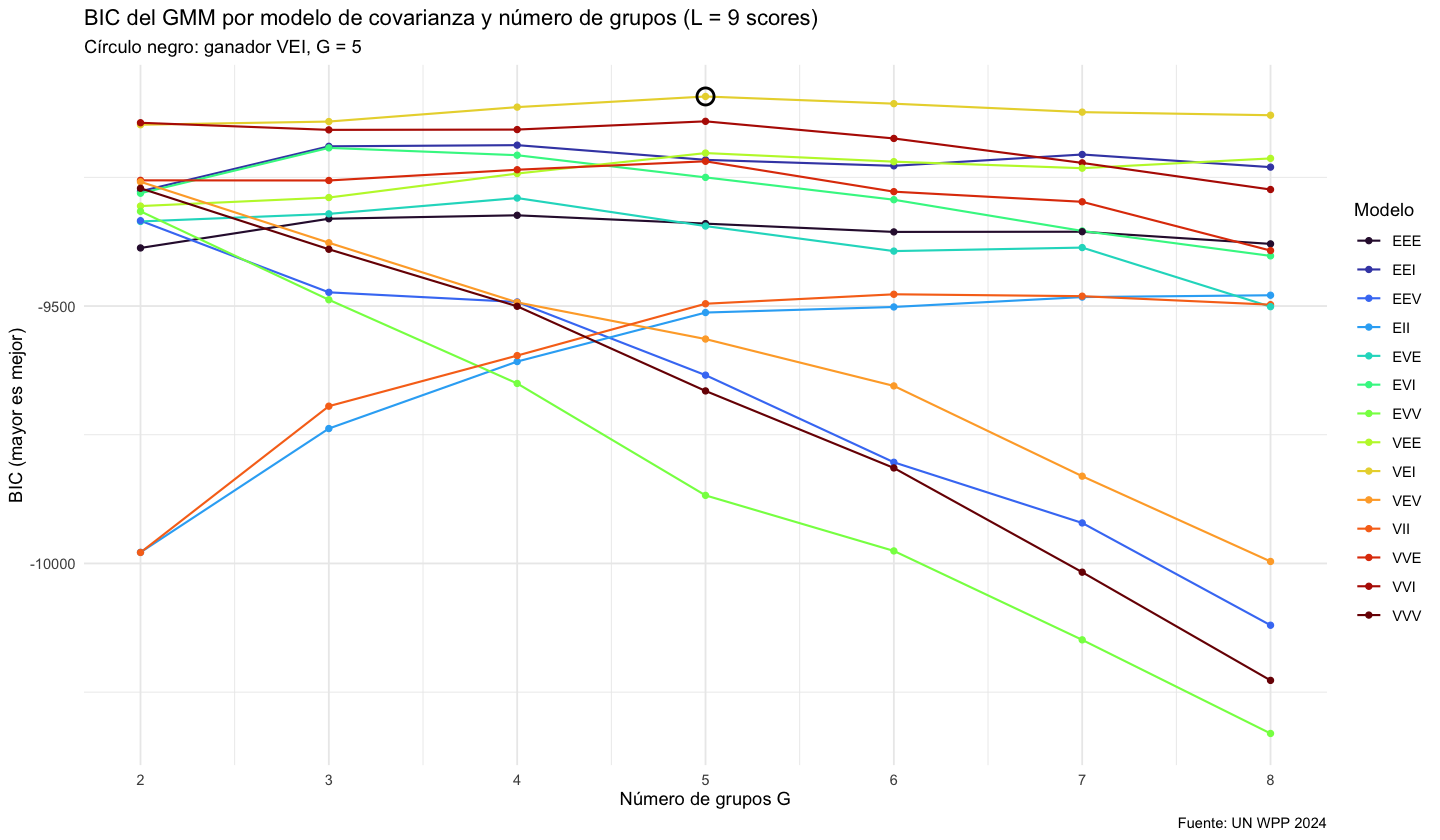

In [2]:
gmm_bic <- mclustBIC(scores, G = G_RANGO, verbose = FALSE)
gmm <- Mclust(scores, x = gmm_bic, verbose = FALSE)
summary(gmm_bic, k = 5) |> print()
cat(sprintf("\nGanador por BIC: modelo %s con G = %d (BIC = %.1f)\n", gmm$modelName, gmm$G, gmm$bic))
print(table(grupo = gmm$classification))

bic_long <- as_tibble(unclass(gmm_bic)[, ], rownames = "G") |> mutate(G = as.integer(G)) |>
  pivot_longer(-G, names_to = "modelo", values_to = "BIC") |> filter(!is.na(BIC))
cat("Modelos sin ajuste (BIC = NA) en alguna G:", sum(is.na(unclass(gmm_bic))), "celdas\n")
p <- ggplot(bic_long, aes(G, BIC, colour = modelo)) +
  geom_line(linewidth = 0.6) + geom_point(size = 1.4) +
  geom_point(data = filter(bic_long, modelo == gmm$modelName, G == gmm$G), colour = "black", size = 4, shape = 21, stroke = 1.2) +
  scale_x_continuous(breaks = G_RANGO) +
  scale_colour_viridis_d(option = "turbo", name = "Modelo") +
  labs(title = "BIC del GMM por modelo de covarianza y número de grupos (L = 9 scores)",
       subtitle = sprintf("Círculo negro: ganador %s, G = %d", gmm$modelName, gmm$G),
       x = "Número de grupos G", y = "BIC (mayor es mejor)", caption = CAPTION) +
  theme_minimal(base_size = 11)
guardar_fig(p, "cl_gmm_bic", w = 10, h = 6); p


In [3]:
clas <- info |> mutate(grupo_gmm = gmm$classification, incertidumbre = gmm$uncertainty)
cat("Distribución de la incertidumbre:\n"); print(round(quantile(clas$incertidumbre, c(0, .5, .75, .9, .95, 1)), 3))
cat("\nPaíses con incertidumbre > 0.2:", sum(clas$incertidumbre > 0.2), "\n")
clas |> arrange(desc(incertidumbre)) |> head(15) |> mutate(incertidumbre = round(incertidumbre, 3)) |>
  as.data.frame() |> print(row.names = FALSE)
cat("\nGrupo GMM × región:\n"); print(table(clas$grupo_gmm, clas$region))


Distribución de la incertidumbre:


   0%   50%   75%   90%   95%  100% 
0.000 0.023 0.118 0.266 0.349 0.639 



Países con incertidumbre > 0.2: 33 


 ISO3_code                         Location                          region grupo_gmm incertidumbre
       IRQ                             Iraq                            Asia         2         0.639
       KEN                            Kenya                          Africa         1         0.554
       LCA                      Saint Lucia Latin America and the Caribbean         2         0.486
       PAN                           Panama Latin America and the Caribbean         2         0.485
       RUS               Russian Federation                          Europe         2         0.442
       KGZ                       Kyrgyzstan                            Asia         2         0.422
       TTO              Trinidad and Tobago Latin America and the Caribbean         4         0.409
       LKA                        Sri Lanka                            Asia         2         0.393
       IRN       Iran (Islamic Republic of)                            Asia         2         0.381



Grupo GMM × región:


   
    Africa Asia Europe Latin America and the Caribbean Northern America Oceania
  1     39    4      0                               1                0       0
  2     13   29      8                              15                0       7
  3      0    1     18                               0                2       2
  4      5   15      1                              17                0       4
  5      0    2     14                               3                0       0


## 3. Ward
Clustering jerárquico aglomerativo sobre la distancia euclídea entre scores, con el criterio de Ward (`ward.D2`): en cada paso une los dos grupos que menos aumentan la suma de cuadrados intra-grupo.


Alturas de las últimas 8 fusiones: 182.4 97.7 70.9 66.2 45.6 45.2 34.7 34.6 


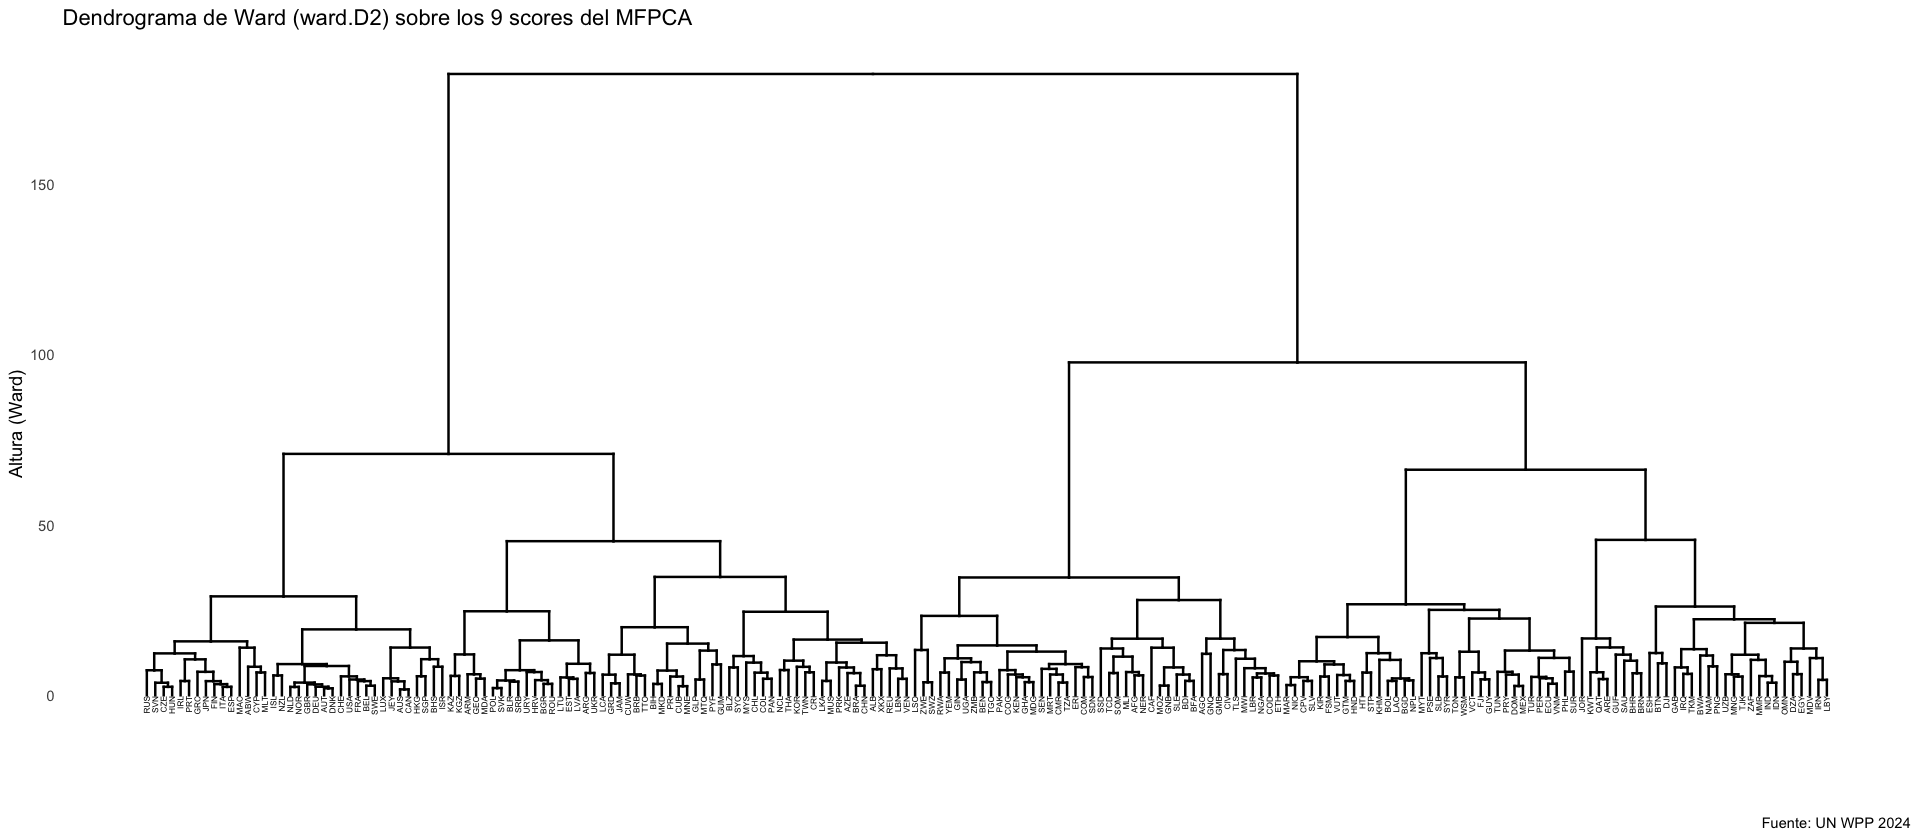

In [4]:
hc <- hclust(dist(scores), method = "ward.D2")
p <- fviz_dend(hc, k = NULL, cex = 0.35, show_labels = TRUE, color_labels_by_k = FALSE,
               main = "Dendrograma de Ward (ward.D2) sobre los 9 scores del MFPCA", ylab = "Altura (Ward)") +
  labs(caption = CAPTION) + theme_minimal(base_size = 11) +
  theme(axis.text.x = element_blank(), panel.grid = element_blank())
options(repr.plot.width = 16, repr.plot.height = 7)
guardar_fig(p, "cl_ward_dendrograma", w = 16, h = 7); p
options(repr.plot.width = 12)
cat("Alturas de las últimas 8 fusiones:", round(rev(tail(hc$height, 8)), 1), "\n")


## 4. k-means
k-means (Hartigan–Wong) con 50 arranques aleatorios para cada $K\in\{2,\dots,8\}$.


In [5]:
set.seed(SEED)
km <- lapply(setNames(G_RANGO, G_RANGO), \(k) kmeans(scores, centers = k, nstart = 50, iter.max = 100))
tibble(K = G_RANGO, tot_withinss = sapply(km, `[[`, "tot.withinss"),
       tamanos = sapply(km, \(m) paste(sort(m$size, decreasing = TRUE), collapse = "/"))) |>
  mutate(tot_withinss = round(tot_withinss, 1)) |> as.data.frame() |> print(row.names = FALSE)


 K tot_withinss                 tamanos
 2      21894.9                  102/98
 3      17134.0                76/72/52
 4      14667.8             61/59/50/30
 5      12852.1          49/47/42/39/23
 6      11948.5       39/39/37/34/28/23
 7      11114.9    38/36/35/35/27/18/11
 8      10370.6 35/34/30/28/25/18/17/13


## 5. Número de grupos: BIC, silueta y gap

- **Silueta media** (Rousseeuw, 1987): para cada país, $s_i=\frac{b_i-a_i}{\max(a_i,b_i)}$, donde $a_i$ es su distancia media a los países de su grupo y $b_i$ la distancia media al grupo vecino más cercano. Se elige el $K$ que maximiza $\bar s$. Valores de $\bar s>0.5$ indican estructura razonable; valores entre 0.25 y 0.5, estructura débil.
- **Estadístico gap** (Tibshirani, Walther y Hastie, 2001): $\mathrm{Gap}(K)=\mathbb E^*\log W_K^*-\log W_K$. $W_K$ es la suma de cuadrados intra-grupo y $\mathbb E^*$ se estima con $B=100$ conjuntos de referencia uniformes sobre la caja de los datos (en la orientación de sus componentes principales). Se elige el menor $K$ con $\mathrm{Gap}(K)\ge\mathrm{Gap}(K+1)-s_{K+1}$ (regla `firstSEmax` de `cluster::maxSE`, la opción por defecto). A diferencia de la silueta, el gap admite $K=1$, es decir, que no haya grupos.
- **BIC:** el $G$ del modelo GMM ganador.

Se calculan para la solución principal ($L=9$) y para la comparación con $\rho_1$–$\rho_4$.


In [6]:
fun_km   <- function(x, k) list(cluster = kmeans(x, k, nstart = 50, iter.max = 100)$cluster)
fun_ward <- function(x, k) list(cluster = cutree(hclust(dist(x), method = "ward.D2"), k))

evaluar_K <- function(S, G_rango = G_RANGO, B = 100, seed = SEED) {
  d <- dist(S); hcS <- hclust(d, method = "ward.D2")
  set.seed(seed); kmS <- lapply(G_rango, \(k) kmeans(S, k, nstart = 50, iter.max = 100)$cluster)
  sil <- tibble(K = G_rango,
                sil_ward   = sapply(G_rango, \(k) mean(silhouette(cutree(hcS, k), d)[, "sil_width"])),
                sil_kmeans = sapply(seq_along(G_rango), \(j) mean(silhouette(kmS[[j]], d)[, "sil_width"])))
  set.seed(seed); gap_km   <- clusGap(S, FUNcluster = fun_km,   K.max = max(G_rango), B = B, verbose = FALSE)
  set.seed(seed); gap_ward <- clusGap(S, FUNcluster = fun_ward, K.max = max(G_rango), B = B, verbose = FALSE)
  set.seed(seed); bic <- mclustBIC(S, G = G_rango, verbose = FALSE)
  g <- Mclust(S, x = bic, verbose = FALSE)
  K_gap <- function(gp) maxSE(gp$Tab[, "gap"], gp$Tab[, "SE.sim"], method = "firstSEmax")
  list(sil = sil, gap_km = gap_km, gap_ward = gap_ward, gmm = g,
       K = c(BIC_gmm = g$G,
             silueta_ward = sil$K[which.max(sil$sil_ward)], silueta_kmeans = sil$K[which.max(sil$sil_kmeans)],
             gap_ward = K_gap(gap_ward), gap_kmeans = K_gap(gap_km)))
}

ev9 <- evaluar_K(scores)
ev4 <- evaluar_K(scores4)
stopifnot(ev9$gmm$G == gmm$G, ev9$gmm$modelName == gmm$modelName)   # coincide con la sección 2

cat("Silueta media por K (L = 9):\n"); print(as.data.frame(ev9$sil |> mutate(across(-K, ~ round(.x, 3)))), row.names = FALSE)
cat("\nSilueta media por K (rho1–rho4):\n"); print(as.data.frame(ev4$sil |> mutate(across(-K, ~ round(.x, 3)))), row.names = FALSE)
gap_tab <- function(ev) tibble(K = 1:max(G_RANGO), gap_ward = ev$gap_ward$Tab[, "gap"], se_ward = ev$gap_ward$Tab[, "SE.sim"],
                               gap_kmeans = ev$gap_km$Tab[, "gap"], se_kmeans = ev$gap_km$Tab[, "SE.sim"])
cat("\nGap por K (L = 9):\n"); print(as.data.frame(gap_tab(ev9) |> mutate(across(-K, ~ round(.x, 3)))), row.names = FALSE)
cat("\nGap por K (rho1–rho4):\n"); print(as.data.frame(gap_tab(ev4) |> mutate(across(-K, ~ round(.x, 3)))), row.names = FALSE)
cat(sprintf("\nGMM con rho1–rho4: %s, G = %d\n", ev4$gmm$modelName, ev4$gmm$G))


Silueta media por K (L = 9):


 K sil_ward sil_kmeans
 2    0.345      0.366
 3    0.271      0.287
 4    0.222      0.292
 5    0.227      0.250
 6    0.229      0.211
 7    0.229      0.220
 8    0.229      0.221



Silueta media por K (rho1–rho4):


 K sil_ward sil_kmeans
 2    0.378      0.411
 3    0.280      0.338
 4    0.229      0.353
 5    0.266      0.311
 6    0.268      0.282
 7    0.260      0.291
 8    0.269      0.290



Gap por K (L = 9):


 K gap_ward se_ward gap_kmeans se_kmeans
 1    0.282   0.014      0.281     0.016
 2    0.382   0.017      0.380     0.013
 3    0.420   0.016      0.415     0.012
 4    0.442   0.016      0.421     0.011
 5    0.464   0.015      0.447     0.012
 6    0.467   0.014      0.456     0.012
 7    0.485   0.014      0.468     0.011
 8    0.491   0.013      0.482     0.011



Gap por K (rho1–rho4):


 K gap_ward se_ward gap_kmeans se_kmeans
 1    0.233   0.020      0.232     0.017
 2    0.313   0.022      0.325     0.018
 3    0.303   0.021      0.359     0.015
 4    0.336   0.022      0.351     0.015
 5    0.360   0.019      0.381     0.015
 6    0.379   0.020      0.389     0.016
 7    0.398   0.020      0.397     0.016
 8    0.418   0.020      0.415     0.016



GMM con rho1–rho4: VVE, G = 3


       criterio L = 9 (principal) rho1–rho4 (comparación)
        BIC_gmm                 5                       3
   silueta_ward                 2                       2
 silueta_kmeans                 2                       2
       gap_ward                 7                       2
     gap_kmeans                 8                       3


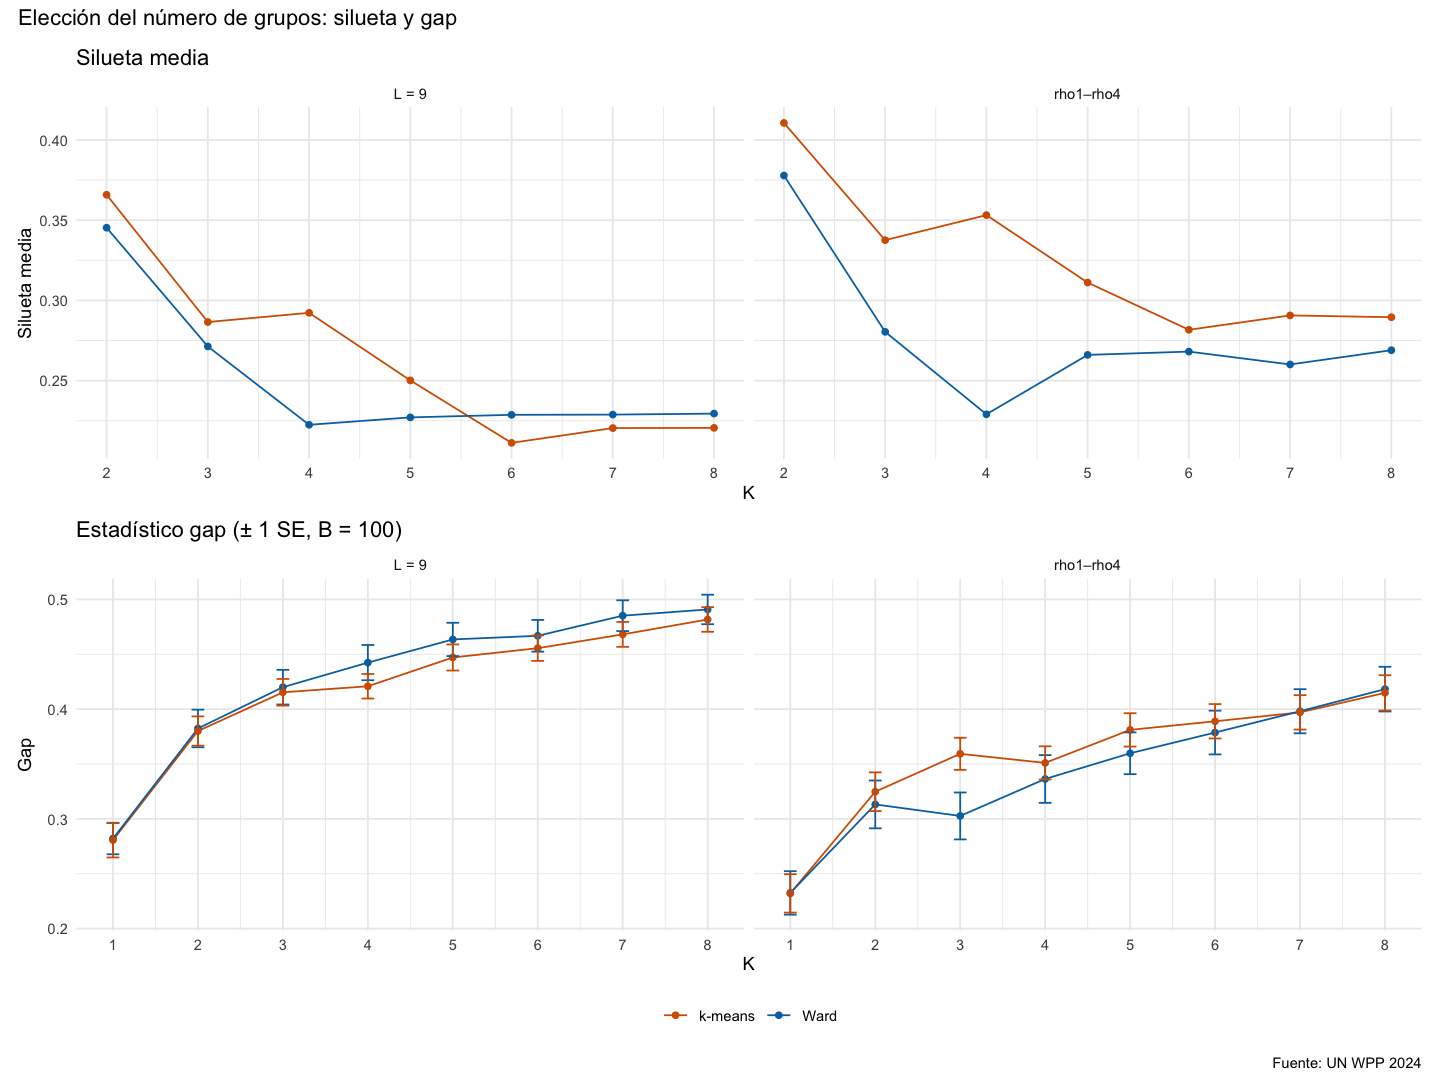

In [7]:
tabla_K <- bind_rows(
  tibble(scores = "L = 9 (principal)", criterio = names(ev9$K), K = unname(ev9$K)),
  tibble(scores = "rho1–rho4 (comparación)", criterio = names(ev4$K), K = unname(ev4$K))) |>
  pivot_wider(names_from = scores, values_from = K)
guardar_tabla(tabla_K, "cluster_eleccion_K", tex = TRUE)
print(as.data.frame(tabla_K), row.names = FALSE)

# Figura: silueta y gap por K
d_sil <- bind_rows(ev9$sil |> mutate(scores = "L = 9"), ev4$sil |> mutate(scores = "rho1–rho4")) |>
  pivot_longer(c(sil_ward, sil_kmeans), names_to = "metodo", values_to = "valor") |>
  mutate(metodo = recode(metodo, sil_ward = "Ward", sil_kmeans = "k-means"))
d_gap <- bind_rows(gap_tab(ev9) |> mutate(scores = "L = 9"), gap_tab(ev4) |> mutate(scores = "rho1–rho4")) |>
  transmute(K, scores, Ward = gap_ward, `k-means` = gap_kmeans, se_w = se_ward, se_k = se_kmeans) |>
  pivot_longer(c(Ward, `k-means`), names_to = "metodo", values_to = "valor") |>
  mutate(se = if_else(metodo == "Ward", se_w, se_k))
p1 <- ggplot(d_sil, aes(K, valor, colour = metodo)) + geom_line() + geom_point() +
  facet_wrap(~ scores) + scale_x_continuous(breaks = G_RANGO) +
  scale_colour_manual(values = c(Ward = "#0072B2", `k-means` = "#D55E00"), name = NULL) +
  labs(title = "Silueta media", x = "K", y = "Silueta media") + theme_minimal(base_size = 11)
p2 <- ggplot(d_gap, aes(K, valor, colour = metodo)) + geom_line() + geom_point() +
  geom_errorbar(aes(ymin = valor - se, ymax = valor + se), width = 0.15) +
  facet_wrap(~ scores) + scale_x_continuous(breaks = 1:max(G_RANGO)) +
  scale_colour_manual(values = c(Ward = "#0072B2", `k-means` = "#D55E00"), name = NULL) +
  labs(title = "Estadístico gap (± 1 SE, B = 100)", x = "K", y = "Gap") + theme_minimal(base_size = 11) +
  guides(colour = "none")
p <- (p1 / p2) + plot_layout(guides = "collect") +
  plot_annotation(title = "Elección del número de grupos: silueta y gap", caption = CAPTION,
                  theme = theme_minimal(base_size = 11)) & theme(legend.position = "bottom")
options(repr.plot.height = 9)
guardar_fig(p, "cl_silueta_gap", w = 11, h = 9); p
options(repr.plot.height = 7)


### Los criterios no coinciden → decisión: $G=5$ con $L=9$

| Criterio | $L=9$ (principal) | $\rho_1$–$\rho_4$ |
|---|---|---|
| BIC (GMM) | **5** (VEI) | **3** (VVE) |
| Silueta, Ward | 2 | 2 |
| Silueta, k-means | 2 | 2 |
| Gap, Ward | 7 | 2 |
| Gap, k-means | 8 | 3 |

**Lectura:**
- **La silueta** favorece $K=2$ en ambos casos, pero con valores bajos (0.35–0.41) que indican estructura débil. Ese $K=2$ es esencialmente un corte del gradiente $\rho_1$ (transición avanzada frente a rezagada).
- **El gap con $L=9$** crece de forma casi monótona hasta $K=8$ (el borde de la rejilla), sin un máximo claro. Es típico de datos con estructura continua más que de grupos bien separados.
- **El BIC** elige $G=5$ con $L=9$ y $G=3$ con $\rho_1$–$\rho_4$. El modelo VEI (volúmenes distintos, misma forma, ejes alineados) es coherente con scores incorrelados.
- Con $\rho_1$–$\rho_4$ hay más acuerdo en torno a $K\in\{2,3\}$: BIC 3, gap k-means 3, silueta 2 y gap Ward 2.

Según la regla del plan, el análisis se detuvo aquí para decidir. **Decisión (2026-10-20): se usa el criterio principal del plan, BIC con GMM, es decir, $G=5$ (VEI) sobre los $L=9$ scores.** Ward y k-means se cortan también en $K=5$ para compararlos. La estructura débil que indican la silueta y el gap se declara explícitamente; la concordancia entre métodos (punto 6) y la estabilidad por bootstrap (punto 7) muestran qué tan robustos son los 5 grupos.


## 6. Concordancia entre métodos ($G=5$)
Se comparan las particiones de GMM, Ward (árbol cortado en 5 grupos) y k-means ($K=5$) con el índice de Rand ajustado:
$$
\mathrm{ARI}=\frac{\mathrm{RI}-\mathbb E[\mathrm{RI}]}{\max\mathrm{RI}-\mathbb E[\mathrm{RI}]},
$$
que vale 1 si las particiones son idénticas y ~0 si coinciden como por azar. No depende de cómo se numeran los grupos. Para facilitar la lectura de las tablas cruzadas, las etiquetas de Ward y k-means se re-numeran para que coincidan lo más posible con las del GMM (asignación húngara, `clue::solve_LSAP`).


In [8]:
G <- gmm$G
alinear <- function(ref, x) {            # re-etiqueta x para maximizar coincidencias con ref
  tab <- table(factor(x, levels = 1:G), factor(ref, levels = 1:G))
  perm <- clue::solve_LSAP(tab, maximum = TRUE)
  as.integer(perm)[x]
}
grupo_gmm    <- gmm$classification
grupo_ward   <- alinear(grupo_gmm, cutree(hc, G))
grupo_kmeans <- alinear(grupo_gmm, km[[as.character(G)]]$cluster)
stopifnot(adjustedRandIndex(grupo_ward, cutree(hc, G)) == 1, adjustedRandIndex(grupo_kmeans, km[[as.character(G)]]$cluster) == 1)

part <- list(GMM = grupo_gmm, Ward = grupo_ward, `k-means` = grupo_kmeans)
ARI <- outer(names(part), names(part), Vectorize(\(a, b) adjustedRandIndex(part[[a]], part[[b]])))
dimnames(ARI) <- list(names(part), names(part))
print(round(ARI, 3))
guardar_tabla(as_tibble(round(ARI, 4), rownames = "metodo"), "cluster_ARI_metodos", tex = TRUE)

cat("\nGMM × Ward:\n");    print(table(GMM = grupo_gmm, Ward = grupo_ward))
cat("\nGMM × k-means:\n"); print(table(GMM = grupo_gmm, kmeans = grupo_kmeans))


          GMM  Ward k-means
GMM     1.000 0.385   0.342
Ward    0.385 1.000   0.616
k-means 0.342 0.616   1.000



GMM × Ward:


   Ward
GMM  1  2  3  4  5
  1 41  1  0  2  0
  2  3 21 12  7 29
  3  0  0 23  0  0
  4  0  8  0 26  8
  5  0  0  1  0 18



GMM × k-means:


   kmeans
GMM  1  2  3  4  5
  1 39  1  0  4  0
  2  0 19 12 17 24
  3  0  0 23  0  0
  4  0  3  0 28 11
  5  0  0 12  0  7


## 7. Estabilidad por bootstrap (`fpc::clusterboot`, $B=500$)
En cada réplica se remuestrean los países con reemplazo, se vuelve a agrupar y, para cada grupo original, se calcula la similitud de Jaccard con el grupo más parecido de la réplica (sobre los países que están en ambas):
$$
J(A,B)=\frac{|A\cap B|}{|A\cup B|}.
$$
El Jaccard medio por grupo mide su estabilidad (Hennig, 2007): **< 0.6 inestable**, 0.6–0.75 con patrón pero dudoso, **> 0.75 estable**.

Se evalúan:
- **k-means** (`kmeansCBI`, $K=5$, 50 arranques por réplica, igual que `nstart = 50`);
- **Ward** (`hclustCBI`, `ward.D2`, $k=5$, `scaling = FALSE` para no reescalar los scores, porque el valor por defecto de `hclustCBI` es `TRUE`);
- **GMM** (`noisemclustCBI` con el modelo VEI y $G=5$ fijos, sin componente de ruido). No lo pide el prompt, pero se agrega porque es el método principal.

Las etiquetas de los grupos de cada método son las de su propia solución sobre los datos completos; para Ward y k-means se muestran re-numeradas como en el punto 6.


In [9]:
t0 <- Sys.time()
cb_km   <- clusterboot(scores, B = B_BOOT, clustermethod = kmeansCBI, krange = G, runs = 50,
                       seed = SEED, count = FALSE)
cb_ward <- clusterboot(scores, B = B_BOOT, clustermethod = hclustCBI, method = "ward.D2", k = G, scaling = FALSE,
                       seed = SEED, count = FALSE)
cb_gmm  <- clusterboot(scores, B = B_BOOT, clustermethod = noisemclustCBI, G = G, modelNames = gmm$modelName, nnk = 0,
                       seed = SEED, count = FALSE)
cat("Tiempo:", format(Sys.time() - t0), "\n")

# Comprobar que las particiones base de clusterboot son las mismas del notebook
stopifnot(adjustedRandIndex(cb_ward$partition, cutree(hc, G)) == 1,
          adjustedRandIndex(cb_gmm$partition, grupo_gmm) == 1)
cat(sprintf("ARI partición base k-means de clusterboot vs k-means (nstart = 50): %.3f\n",
            adjustedRandIndex(cb_km$partition, km[[as.character(G)]]$cluster)))

estab <- function(cb, ref_lab, metodo) {
  lab <- if (is.null(ref_lab)) seq_along(cb$bootmean) else alinear(grupo_gmm, cb$partition)[match(seq_along(cb$bootmean), cb$partition)]
  tibble(metodo = metodo, grupo = lab, n = as.integer(table(cb$partition)[as.character(seq_along(cb$bootmean))]),
         jaccard_medio = cb$bootmean, disoluciones = cb$bootbrd, recuperaciones = cb$bootrecover) |>
    mutate(estado = case_when(jaccard_medio > 0.75 ~ "estable", jaccard_medio >= 0.6 ~ "dudoso", TRUE ~ "inestable")) |>
    arrange(grupo)
}
tabla_estab <- bind_rows(estab(cb_gmm, NULL, "GMM"), estab(cb_ward, TRUE, "Ward"), estab(cb_km, TRUE, "k-means"))
guardar_tabla(tabla_estab |> mutate(jaccard_medio = round(jaccard_medio, 3)), "cluster_estabilidad", tex = TRUE)
tabla_estab |> mutate(jaccard_medio = round(jaccard_medio, 3)) |> as.data.frame() |> print(row.names = FALSE)


Tiempo: 5.295382 secs 


ARI partición base k-means de clusterboot vs k-means (nstart = 50): 1.000


  metodo grupo  n jaccard_medio disoluciones recuperaciones    estado
     GMM     1 44         0.775           70            316   estable
     GMM     2 72         0.631           90             95    dudoso
     GMM     3 23         0.797           43            324   estable
     GMM     4 42         0.590          176             96 inestable
     GMM     5 19         0.514          271            135 inestable
    Ward     1 44         0.850           12            408   estable
    Ward     2 30         0.513          303             99 inestable
    Ward     3 36         0.747           23            222    dudoso
    Ward     4 35         0.543          228             42 inestable
    Ward     5 55         0.621          136            122    dudoso
 k-means     1 39         0.903            0            480   estable
 k-means     2 23         0.811           48            342   estable
 k-means     3 47         0.939            1            471   estable
 k-means     4 49   

## 8a. Plano $\rho_1$–$\rho_2$ por grupo GMM
Cada punto es un país, coloreado por su grupo GMM. Las elipses son las regiones del 95 % de cada componente de la mezcla, proyectadas en el plano $(\rho_1,\rho_2)$: media $\hat{\boldsymbol\mu}_g$ y submatriz $2\times2$ de $\hat{\boldsymbol\Sigma}_g$. Se etiquetan los 15 países con mayor incertidumbre de clasificación. Como el modelo usa 9 dimensiones, dos grupos pueden solaparse en este plano y separarse en $\rho_3$–$\rho_9$.


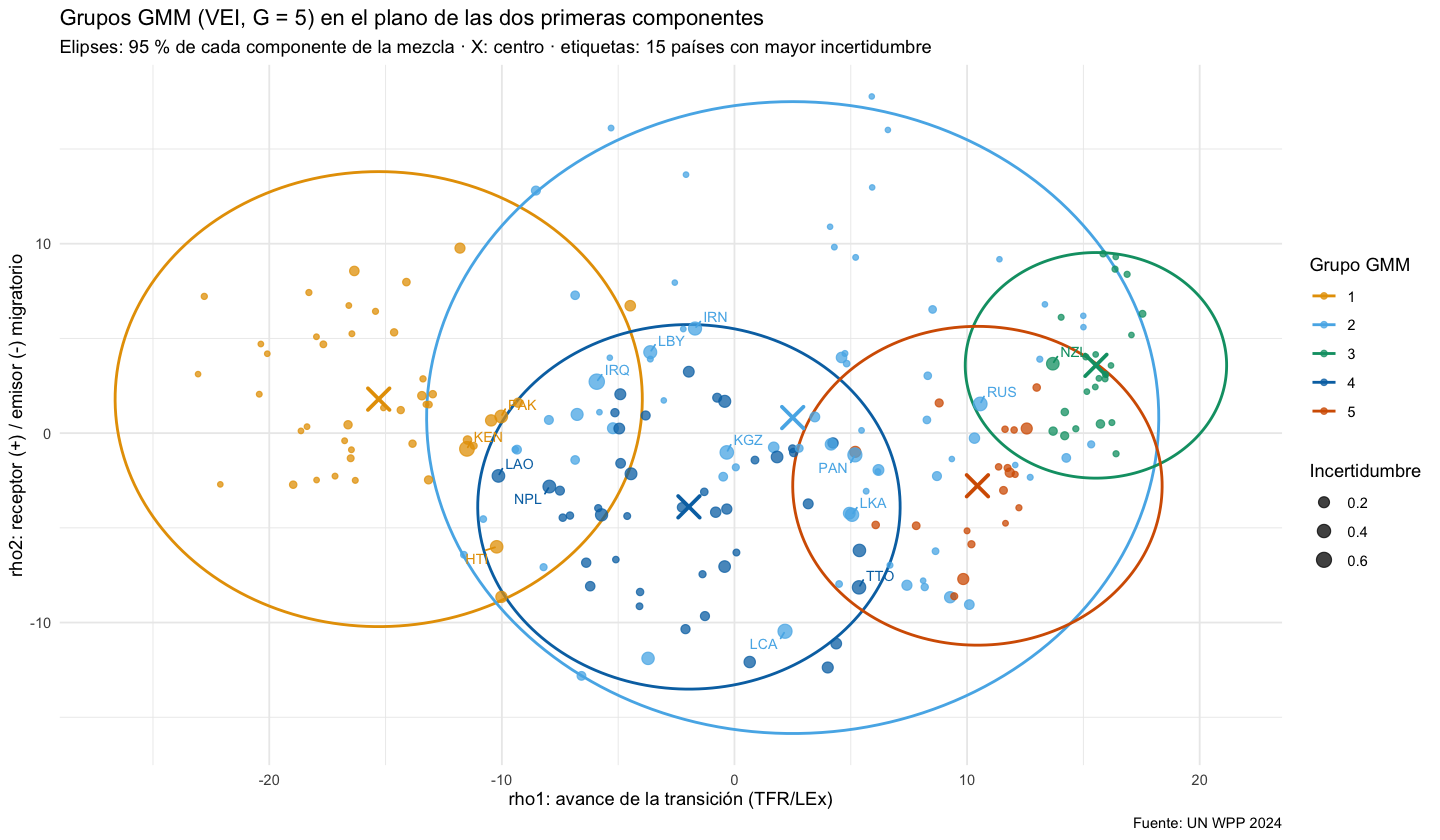

In [10]:
elipse <- function(mu, S, nivel = 0.95, n = 200) {
  ang <- seq(0, 2 * pi, length.out = n); r <- sqrt(qchisq(nivel, 2))
  e <- eigen(S); pts <- t(mu + e$vectors %*% diag(sqrt(e$values)) %*% rbind(cos(ang), sin(ang)) * r)
  tibble(rho1 = pts[, 1], rho2 = pts[, 2])
}
elipses <- map_dfr(1:G, \(g) elipse(gmm$parameters$mean[1:2, g], gmm$parameters$variance$sigma[1:2, 1:2, g]) |>
                     mutate(grupo = factor(g)))
d8 <- as_tibble(scores[, 1:2]) |> mutate(ISO3_code = info$ISO3_code, grupo = factor(grupo_gmm),
                                          incertidumbre = gmm$uncertainty)
top15 <- d8 |> slice_max(incertidumbre, n = 15)
centros <- tibble(grupo = factor(1:G), rho1 = gmm$parameters$mean[1, ], rho2 = gmm$parameters$mean[2, ])

p <- ggplot(d8, aes(rho1, rho2, colour = grupo)) +
  geom_path(data = elipses, aes(group = grupo), linewidth = 0.8) +
  geom_point(aes(size = incertidumbre), alpha = 0.75) +
  geom_point(data = centros, shape = 4, size = 5, stroke = 1.6, show.legend = FALSE) +
  ggrepel::geom_text_repel(data = top15, aes(label = ISO3_code), size = 3, seed = SEED, max.overlaps = Inf,
                           show.legend = FALSE, min.segment.length = 0) +
  scale_colour_manual(values = OKABE[c(1, 2, 3, 5, 6)], name = "Grupo GMM") +
  scale_size_continuous(range = c(1.2, 4), name = "Incertidumbre") +
  labs(title = sprintf("Grupos GMM (%s, G = %d) en el plano de las dos primeras componentes", gmm$modelName, G),
       subtitle = "Elipses: 95 % de cada componente de la mezcla · X: centro · etiquetas: 15 países con mayor incertidumbre",
       x = "rho1: avance de la transición (TFR/LEx)", y = "rho2: receptor (+) / emisor (-) migratorio", caption = CAPTION) +
  theme_minimal(base_size = 11)
guardar_fig(p, "cl_gmm_rho1_rho2", w = 11, h = 7.5); p


## 8b. Silueta de la solución elegida (GMM, $G=5$)
Silueta de cada país con la partición GMM y la distancia euclídea entre los 9 scores. Valores negativos indican países más cerca, en promedio, de otro grupo que del suyo. La silueta favorece grupos esféricos y compactos, así que penaliza al GMM, cuyas componentes tienen volúmenes distintos (modelo VEI). Por eso se lee como un diagnóstico, no como un criterio para elegir el método.


 grupo  n sil_media negativos
     1 44     0.370         2
     2 72    -0.232        68
     3 23     0.473         0
     4 42     0.315         1
     5 19     0.282         1


Silueta media global (GMM): 0.145 | países con s < 0: 72


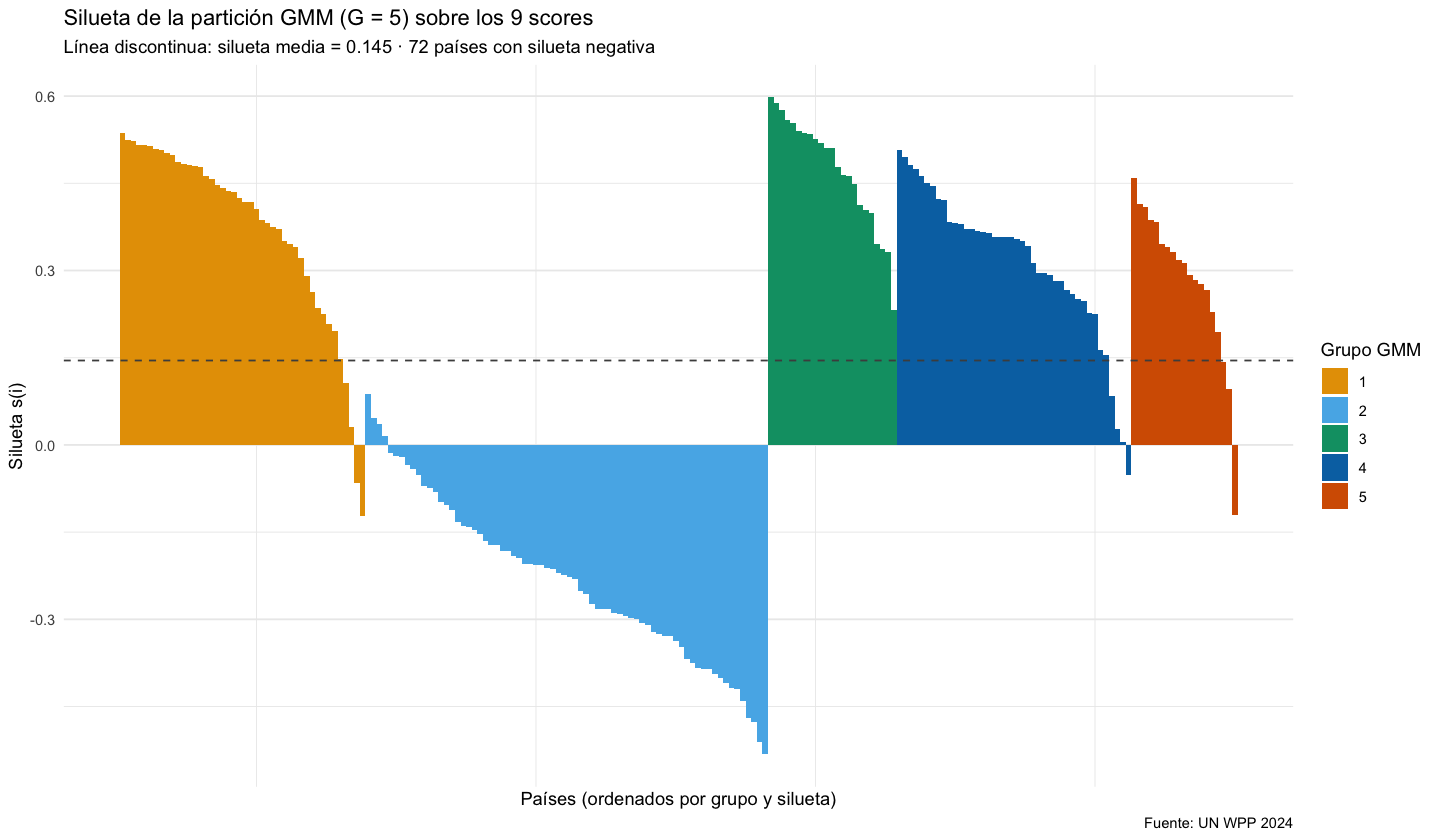

In [11]:
sil_gmm <- silhouette(grupo_gmm, dist(scores))
d_sil <- tibble(ISO3_code = info$ISO3_code, grupo = factor(sil_gmm[, "cluster"]), s = sil_gmm[, "sil_width"]) |>
  arrange(grupo, desc(s)) |> mutate(orden = row_number())
res_sil <- d_sil |> group_by(grupo) |> summarise(n = n(), sil_media = mean(s), negativos = sum(s < 0), .groups = "drop")
print(as.data.frame(res_sil |> mutate(sil_media = round(sil_media, 3))), row.names = FALSE)
cat(sprintf("Silueta media global (GMM): %.3f | países con s < 0: %d\n", mean(d_sil$s), sum(d_sil$s < 0)))

p <- ggplot(d_sil, aes(orden, s, fill = grupo)) +
  geom_col(width = 1) +
  geom_hline(yintercept = mean(d_sil$s), linetype = "dashed", colour = "grey30") +
  scale_fill_manual(values = OKABE[c(1, 2, 3, 5, 6)], name = "Grupo GMM") +
  labs(title = sprintf("Silueta de la partición GMM (G = %d) sobre los 9 scores", G),
       subtitle = sprintf("Línea discontinua: silueta media = %.3f · %d países con silueta negativa", mean(d_sil$s), sum(d_sil$s < 0)),
       x = "Países (ordenados por grupo y silueta)", y = "Silueta s(i)", caption = CAPTION) +
  theme_minimal(base_size = 11) + theme(axis.text.x = element_blank(), panel.grid.major.x = element_blank())
guardar_fig(p, "cl_silueta_gmm", w = 11, h = 5.5); p


## 8c. Mapa mundial de los grupos GMM
Cada país se colorea según su grupo GMM ($G=5$). Se usan las unidades cartográficas de Natural Earth (`rnaturalearth`, escala media, `type = "map_units"`), que separan los departamentos de ultramar franceses (Guayana Francesa, Guadalupe, Martinica, Reunión, Mayotte) del territorio metropolitano, porque en WPP son ubicaciones propias. La unión se hace por código ISO3 (`iso_a3_eh`), con una corrección para Kosovo (Natural Earth usa `KOS`; WPP, `XKX`). En gris aparecen los países pequeños excluidos (< 100 mil habitantes) y los territorios sin dato propio en WPP (por ejemplo, Somalilandia o el norte de Chipre). Proyección: Robinson.

Grupos (ver conclusiones):
1. transición tardía;
2. trayectorias idiosincráticas;
3. transición temprana y receptores;
4. transición intermedia y rápida, emisores;
5. transición temprana con estancamiento y reversión migratoria.


Unidades cartográficas coloreadas: 214 | países WPP representados: 200 de 200 


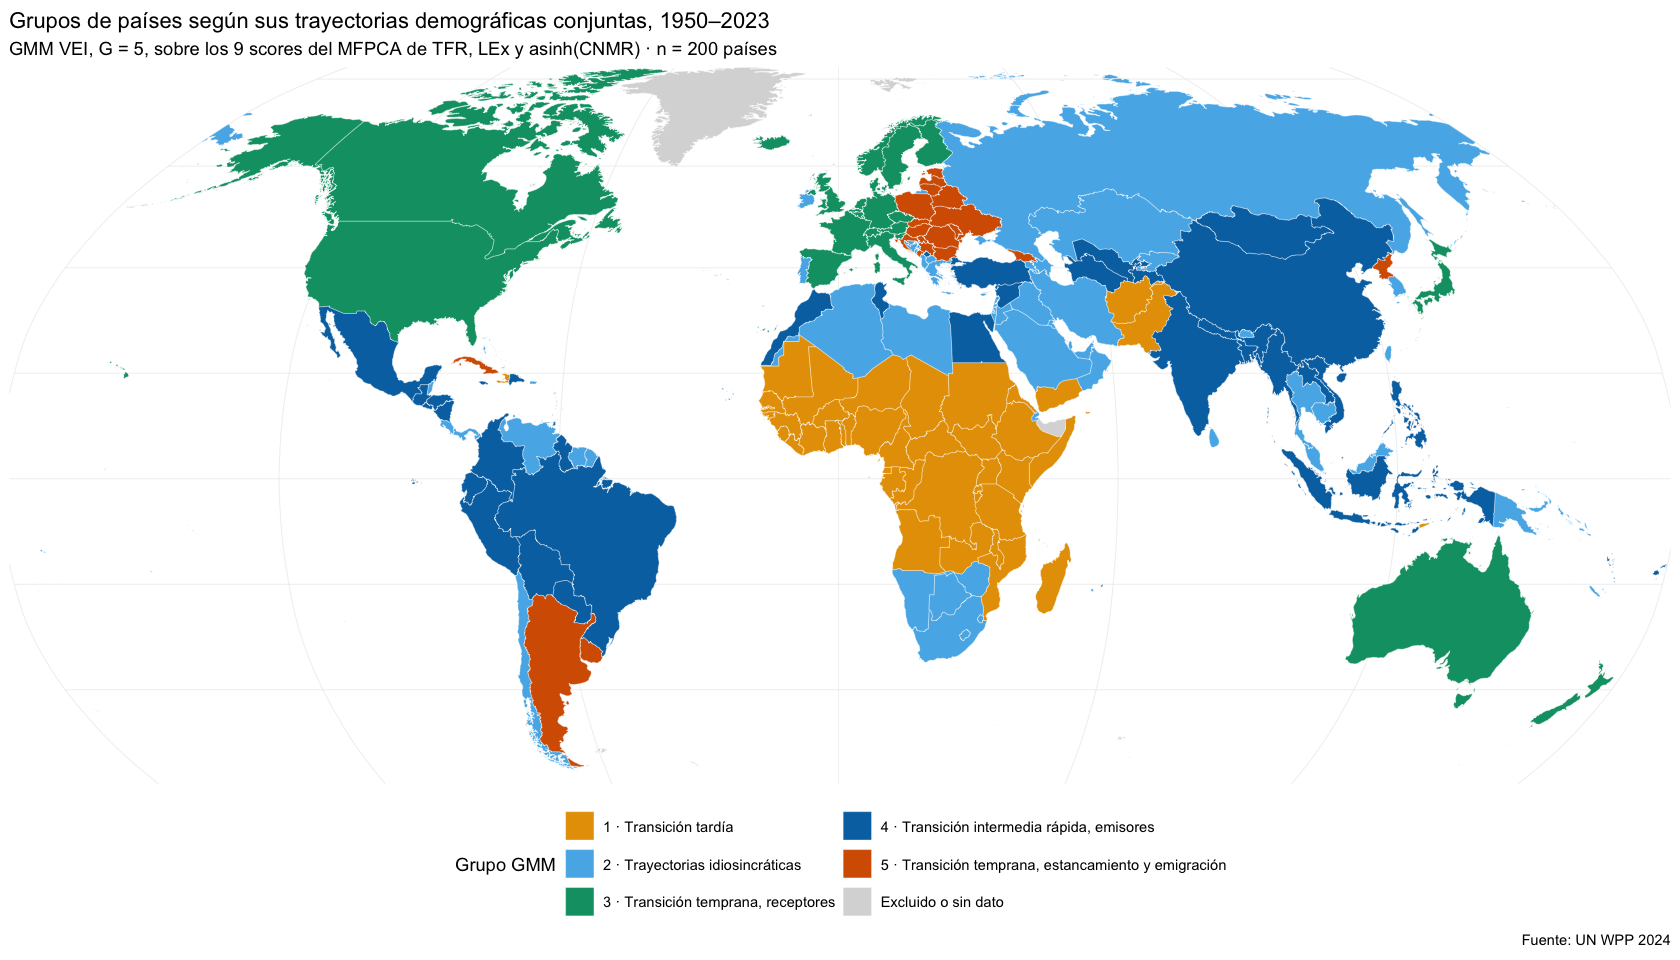

In [12]:
suppressPackageStartupMessages(library(sf))
mundo <- rnaturalearth::ne_countries(scale = "medium", type = "map_units", returnclass = "sf") |>
  filter(continent != "Antarctica") |>
  mutate(ISO3_code = case_when(gu_a3 == "KOS" ~ "XKX", TRUE ~ iso_a3_eh))
stopifnot(all(info$ISO3_code %in% mundo$ISO3_code))   # los 200 países tienen polígono

ETIQ_GRUPO <- c(`1` = "1 · Transición tardía",
                `2` = "2 · Trayectorias idiosincráticas",
                `3` = "3 · Transición temprana, receptores",
                `4` = "4 · Transición intermedia rápida, emisores",
                `5` = "5 · Transición temprana, estancamiento y emigración")
mapa <- mundo |>
  left_join(tibble(ISO3_code = info$ISO3_code, grupo = factor(ETIQ_GRUPO[as.character(grupo_gmm)], levels = ETIQ_GRUPO)),
            by = "ISO3_code")
cat("Unidades cartográficas coloreadas:", sum(!is.na(mapa$grupo)), "| países WPP representados:",
    n_distinct(mapa$ISO3_code[!is.na(mapa$grupo)]), "de", nrow(info), "\n")
SIN_DATO <- "Excluido o sin dato"
mapa <- mapa |> mutate(grupo = factor(if_else(is.na(grupo), SIN_DATO, as.character(grupo)), levels = c(ETIQ_GRUPO, SIN_DATO)))

p <- ggplot(mapa) +
  geom_sf(aes(fill = grupo), colour = "white", linewidth = 0.1) +
  scale_fill_manual(values = setNames(c(OKABE[c(1, 2, 3, 5, 6)], "grey85"), c(ETIQ_GRUPO, SIN_DATO)),
                    name = "Grupo GMM", guide = guide_legend(ncol = 2)) +
  coord_sf(crs = "+proj=robin", expand = FALSE) +
  labs(title = "Grupos de países según sus trayectorias demográficas conjuntas, 1950–2023",
       subtitle = sprintf("GMM %s, G = %d, sobre los 9 scores del MFPCA de TFR, LEx y asinh(CNMR) · n = 200 países",
                          gmm$modelName, G),
       caption = CAPTION) +
  theme_minimal(base_size = 11) +
  theme(legend.position = "bottom", panel.grid = element_line(colour = "grey92", linewidth = 0.2),
        axis.text = element_blank())
options(repr.plot.width = 14, repr.plot.height = 8)
guardar_fig(p, "cl_mapa_grupos_gmm", w = 14, h = 8); p
options(repr.plot.width = 12, repr.plot.height = 7)


## 9. Guardado
- `clusters_principal.rds`: una fila por país con `ISO3_code`, `Location`, región, `grupo_gmm`, `incertidumbre`, `grupo_ward` y `grupo_kmeans` (re-numerados según el GMM), más los 9 scores.
- `cluster_resumen.csv`: tamaño de cada grupo GMM y media de cada score.

También se listan los miembros de cada grupo y su composición por región como apoyo para la interpretación.


In [13]:
clusters <- info |>
  mutate(grupo_gmm = grupo_gmm, incertidumbre = gmm$uncertainty, grupo_ward = grupo_ward, grupo_kmeans = grupo_kmeans) |>
  bind_cols(as_tibble(scores))
stopifnot(nrow(clusters) == 200, !anyNA(clusters))
saveRDS(clusters, here::here("output/data/clusters_principal.rds"))

cluster_resumen <- clusters |> group_by(grupo_gmm) |>
  summarise(n = n(), incert_media = mean(incertidumbre), across(starts_with("rho"), mean), .groups = "drop")
guardar_tabla(cluster_resumen |> mutate(across(where(is.double), ~ round(.x, 3))), "cluster_resumen", tex = TRUE)
cluster_resumen |> mutate(across(where(is.double), ~ round(.x, 2))) |> as.data.frame() |> print(row.names = FALSE)

cat("\nComposición por región (GMM):\n"); print(table(grupo = clusters$grupo_gmm, clusters$region))
cat("\nMiembros por grupo GMM (ordenados por incertidumbre creciente):\n")
for (g in 1:G) {
  m <- clusters |> filter(grupo_gmm == g) |> arrange(incertidumbre)
  cat(sprintf("\nGrupo %d (n = %d): %s\n", g, nrow(m), paste(m$ISO3_code, collapse = ", ")))
}


 grupo_gmm  n incert_media   rho1  rho2  rho3  rho4  rho5  rho6  rho7  rho8  rho9
         1 44         0.06 -15.30  1.75 -2.61  0.25  0.53 -0.04  0.07  0.54  0.37
         2 72         0.10   2.84  0.95  1.99  0.95 -0.05 -0.23 -0.10 -0.65  0.22
         3 23         0.02  15.57  3.63 -3.02  0.88  1.00  0.35  0.27  0.97 -0.10
         4 42         0.14  -2.10 -4.19  2.64 -0.66 -0.92  0.54  0.01 -0.12 -0.44
         5 19         0.05  10.47 -2.79 -3.66 -3.76 -0.20 -0.67 -0.11  0.30 -0.61



Composición por región (GMM):


     
grupo Africa Asia Europe Latin America and the Caribbean Northern America Oceania
    1     39    4      0                               1                0       0
    2     13   29      8                              15                0       7
    3      0    1     18                               0                2       2
    4      5   15      1                              17                0       4
    5      0    2     14                               3                0       0



Miembros por grupo GMM (ordenados por incertidumbre creciente):



Grupo 1 (n = 44): NER, MLI, TCD, BFA, BDI, SOM, SLE, COD, NGA, BEN, AFG, GIN, UGA, ETH, MOZ, GNB, CMR, LBR, AGO, SSD, TZA, TGO, MWI, RWA, MRT, ERI, TLS, ZMB, MDG, CAF, GMB, COM, YEM, SEN, SDN, COG, CIV, GNQ, GAB, STP, GHA, HTI, PAK, KEN

Grupo 2 (n = 72): MAC, QAT, ARE, ISR, GUF, OMN, KWT, JOR, IRL, ABW, MYT, HKG, SGP, MTQ, BWA, SAU, SYC, ZAF, REU, BHR, ESH, BRN, PYF, NCL, MDV, PRT, GLP, CYP, LSO, MYS, ZWE, GUM, SWZ, CUW, BLZ, PSE, GRC, BIH, CRI, BHS, KOR, VEN, BTN, SLB, MLT, SUR, WSM, KHM, NAM, DJI, CHL, PRI, KAZ, MKD, TWN, AZE, THA, ARM, DZA, BRB, LBN, ALB, PNG, TON, LBY, IRN, LKA, KGZ, RUS, PAN, LCA, IRQ

Grupo 3 (n = 23): NOR, SWE, BEL, LUX, GBR, DNK, AUT, USA, ITA, NLD, DEU, JEY, JPN, FIN, FRA, CAN, AUS, CHE, SVN, ISL, CZE, ESP, NZL

Grupo 4 (n = 42): NIC, SLV, MAR, MEX, DOM, HND, BGD, CPV, GTM, PER, ECU, VNM, EGY, BRA, IDN, BOL, IND, FJI, GUY, KIR, PHL, FSM, MMR, COL, XKX, CHN, TUN, JAM, TJK, TKM, MNG, GRD, VCT, PRY, TUR, SYR, UZB, VUT, MUS, LAO, NPL, TTO

Grupo 5 (n = 19): BGR,

# Función reutilizable

`correr_clustering(scores, G_rango, seed)` encapsula el flujo de este notebook para la sensibilidad (F8):
1. GMM con `mclustBIC` en `G_rango` → modelo y $G$ por BIC, clasificación e incertidumbre;
2. Ward (`ward.D2`) y k-means (`nstart = 50`) cortados en ese mismo $G$ y re-etiquetados para alinearse con el GMM;
3. matriz de ARI entre los tres métodos;
4. silueta media y gap ($B$ = `B_gap`, regla `firstSEmax`) para Ward y k-means, y la tabla de $K$ por criterio;
5. opcionalmente (`B_boot > 0`), estabilidad por `clusterboot` para GMM, Ward y k-means.

Es autocontenida (todas las llamadas con `paquete::`) y reproduce la misma secuencia de números aleatorios que este notebook. Acepta `G` fijo (`G = NULL` = elegir por BIC), para que en F8 se pueda comparar con el mismo $G$ de la solución principal.


In [14]:
correr_clustering <- function(scores, G_rango = 2:8, seed = 20261014, G = NULL, B_gap = 100, B_boot = 0) {
  mclustBIC <- mclust::mclustBIC   # Mclust() evalúa una llamada a mclustBIC en el entorno que lo invoca
  scores <- as.matrix(scores)
  d  <- stats::dist(scores)
  hc <- stats::hclust(d, method = "ward.D2")
  set.seed(seed)
  km <- lapply(G_rango, function(k) stats::kmeans(scores, centers = k, nstart = 50, iter.max = 100))
  names(km) <- G_rango

  # 1. GMM por BIC (G fijo opcional)
  bic <- mclust::mclustBIC(scores, G = if (is.null(G)) G_rango else G, verbose = FALSE)
  gmm <- mclust::Mclust(scores, x = bic, verbose = FALSE)
  Gs  <- gmm$G
  if (!Gs %in% G_rango) stop("G = ", Gs, " fuera de G_rango")

  # 2. Ward y k-means en el mismo G, alineados con el GMM
  alinear <- function(ref, x) {
    tab  <- table(factor(x, levels = 1:Gs), factor(ref, levels = 1:Gs))
    as.integer(clue::solve_LSAP(tab, maximum = TRUE))[x]
  }
  g_gmm  <- gmm$classification
  g_ward <- alinear(g_gmm, stats::cutree(hc, Gs))
  g_km   <- alinear(g_gmm, km[[as.character(Gs)]]$cluster)

  # 3. ARI
  part <- list(GMM = g_gmm, Ward = g_ward, `k-means` = g_km)
  ARI <- outer(names(part), names(part), Vectorize(function(a, b) mclust::adjustedRandIndex(part[[a]], part[[b]])))
  dimnames(ARI) <- list(names(part), names(part))

  # 4. Silueta y gap
  sil_media <- function(cl) mean(cluster::silhouette(cl, d)[, "sil_width"])
  sil <- tibble::tibble(K = G_rango,
                        sil_ward   = sapply(G_rango, function(k) sil_media(stats::cutree(hc, k))),
                        sil_kmeans = sapply(as.character(G_rango), function(k) sil_media(km[[k]]$cluster)))
  K_crit <- c(BIC_gmm = Gs, silueta_ward = sil$K[which.max(sil$sil_ward)], silueta_kmeans = sil$K[which.max(sil$sil_kmeans)])
  gap <- NULL
  if (B_gap > 0) {
    f_km   <- function(x, k) list(cluster = stats::kmeans(x, k, nstart = 50, iter.max = 100)$cluster)
    f_ward <- function(x, k) list(cluster = stats::cutree(stats::hclust(stats::dist(x), method = "ward.D2"), k))
    set.seed(seed); gap_km   <- cluster::clusGap(scores, FUNcluster = f_km,   K.max = max(G_rango), B = B_gap, verbose = FALSE)
    set.seed(seed); gap_ward <- cluster::clusGap(scores, FUNcluster = f_ward, K.max = max(G_rango), B = B_gap, verbose = FALSE)
    kg <- function(gp) cluster::maxSE(gp$Tab[, "gap"], gp$Tab[, "SE.sim"], method = "firstSEmax")
    K_crit <- c(K_crit, gap_ward = kg(gap_ward), gap_kmeans = kg(gap_km))
    gap <- list(ward = gap_ward, kmeans = gap_km)
  }

  # 5. Estabilidad (opcional)
  estab <- NULL
  if (B_boot > 0) {
    cb <- list(
      GMM  = fpc::clusterboot(scores, B = B_boot, clustermethod = fpc::noisemclustCBI, G = Gs, modelNames = gmm$modelName,
                              nnk = 0, seed = seed, count = FALSE),
      Ward = fpc::clusterboot(scores, B = B_boot, clustermethod = fpc::hclustCBI, method = "ward.D2", k = Gs,
                              scaling = FALSE, seed = seed, count = FALSE),
      `k-means` = fpc::clusterboot(scores, B = B_boot, clustermethod = fpc::kmeansCBI, krange = Gs, runs = 50,
                                   seed = seed, count = FALSE))
    estab <- dplyr::bind_rows(lapply(names(cb), function(mt) {
      x <- cb[[mt]]; k <- seq_along(x$bootmean)
      lab <- if (mt == "GMM") k else alinear(g_gmm, x$partition)[match(k, x$partition)]
      tibble::tibble(metodo = mt, grupo = lab, n = as.integer(table(x$partition)[as.character(k)]),
                     jaccard_medio = x$bootmean, disoluciones = x$bootbrd, recuperaciones = x$bootrecover)
    }))
    estab <- estab[order(match(estab$metodo, names(cb)), estab$grupo), ]
  }

  list(G = Gs, modelo = gmm$modelName, gmm = gmm, bic = bic, hc = hc, kmeans = km,
       grupos = tibble::tibble(fila = rownames(scores), grupo_gmm = g_gmm, incertidumbre = gmm$uncertainty,
                               grupo_ward = g_ward, grupo_kmeans = g_km),
       ARI = ARI, silueta = sil, gap = gap, K_criterios = K_crit, estabilidad = estab,
       config = list(G_rango = G_rango, seed = seed, G_fijo = G, B_gap = B_gap, B_boot = B_boot))
}


### Prueba: reproducir la solución principal
Se ejecuta la función sobre los mismos scores y se comparan $G$, el modelo, las tres particiones, el ARI, la tabla de $K$ y el Jaccard de estabilidad. Después se guarda en `output/data/funciones_clustering.rds` y se vuelve a comprobar cargándola en un entorno limpio, sin acceso a los objetos del notebook.


In [15]:
mismo <- function(a, b) identical(as.integer(unname(a)), as.integer(unname(b)))
prueba <- correr_clustering(scores, G_rango = G_RANGO, seed = SEED, B_gap = 100, B_boot = B_BOOT)
stopifnot(prueba$G == G, prueba$modelo == gmm$modelName,
          mismo(prueba$grupos$grupo_gmm, grupo_gmm),
          mismo(prueba$grupos$grupo_ward, grupo_ward), mismo(prueba$grupos$grupo_kmeans, grupo_kmeans),
          max(abs(prueba$ARI - ARI)) < 1e-12,
          identical(unname(prueba$K_criterios), unname(ev9$K)),
          max(abs(prueba$estabilidad$jaccard_medio - tabla_estab$jaccard_medio)) < 1e-12)
cat("La función reproduce G, modelo, particiones, ARI, criterios de K y estabilidad.\n")

saveRDS(list(correr_clustering = correr_clustering), here::here("output/data/funciones_clustering.rds"))
f_cargada <- readRDS(here::here("output/data/funciones_clustering.rds"))$correr_clustering
environment(f_cargada) <- new.env(parent = baseenv())
prueba2 <- f_cargada(scores, G_rango = G_RANGO, seed = SEED, B_gap = 0)
stopifnot(mismo(prueba2$grupos$grupo_gmm, grupo_gmm), mismo(prueba2$grupos$grupo_kmeans, grupo_kmeans))
cat("funciones_clustering.rds guardado y verificado en un entorno limpio.\n")


La función reproduce G, modelo, particiones, ARI, criterios de K y estabilidad.


funciones_clustering.rds guardado y verificado en un entorno limpio.


# Conclusiones de F6

**Solución elegida:** GMM `mclust` VEI con $G=5$ sobre los $L=9$ scores del MFPCA, elegido por BIC (decisión del 2026-10-20, ya que BIC, silueta y gap no coincidían).

| Grupo | n | Perfil de scores | Composición | Ejemplos | Jaccard (GMM) |
|---|---|---|---|---|---|
| 1 | 44 | $\rho_1=-15.3$: transición tardía, con fecundidad y mortalidad altas persistentes | 39 África, 4 Asia, Haití | Níger, Malí, Chad, Somalia, Afganistán, Yemen, Pakistán | **0.78 estable** |
| 3 | 23 | $\rho_1=+15.6$, $\rho_2=+3.6$: transición temprana y completa; receptores netos | Europa occidental, Northern America, Japón, Australia, Nueva Zelanda | Noruega, Suecia, EE. UU., Japón, Alemania, Francia | **0.80 estable** |
| 5 | 19 | $\rho_1=+10.5$, $\rho_3=-3.7$, $\rho_4=-3.8$: transición temprana con trayectoria estancada y **reversión migratoria hacia la emigración** desde ~1990 | Europa del Este postsocialista, Cono Sur, Cuba | Bulgaria, Rumanía, Ucrania, Bálticos, Polonia, Uruguay, Argentina, Cuba | 0.51 inestable |
| 4 | 42 | $\rho_1=-2.1$, $\rho_2=-4.2$, $\rho_3=+2.6$: transición intermedia y rápida; **emisores netos** | América Latina, sur y sudeste de Asia, norte de África | México, Brasil, Colombia, India, Indonesia, Vietnam, China, Egipto | 0.59 inestable |
| 2 | 72 | Cerca del centro en $\rho_1$, pero con alta dispersión en todas las componentes | Mixto: Golfo, territorios insulares, Asia de alto crecimiento, África austral con VIH, países en crisis | Qatar, EAU, Singapur, Corea, Botsuana, Sudáfrica, Líbano, Irak | 0.63 dudoso |

**Lectura.**
- **Grupos 1 y 3 (los polos de la transición):** son estables en el GMM.
  - El grupo 1 aparece casi idéntico con los otros métodos: Ward conserva 41 de sus 44 países (Jaccard 0.85) y k-means 39 (Jaccard 0.90).
  - El grupo 3 queda entero dentro de un grupo de k-means más amplio (47 países, Jaccard 0.94), que también incluye 12 países del grupo 2 y 12 del grupo 5.
- **Grupos 4 y 5:** separan trayectorias que un corte transversal confundiría.
  - El grupo 5 reúne países con un nivel de transición alto, parecido al del grupo 3, pero con estancamiento y reversión migratoria.
  - El grupo 4 reúne transiciones rápidas en países emisores.
  - Son interpretables, pero **inestables en el GMM** (Jaccard 0.51–0.59). k-means produce otra partición (ARI 0.34 con el GMM) cuyos 5 grupos son todos estables (0.76–0.94), pero que reparte de otro modo a los países del grupo 2 y del grupo 5.
- **El grupo 2 es una componente "de fondo"** de gran volumen (VEI permite volúmenes distintos) que absorbe las trayectorias atípicas en alguna dimensión: inmigración extrema del Golfo, alcance acelerado del este de Asia, la firma del VIH/sida y crisis. Por eso 68 de sus 72 países tienen silueta negativa. Es un grupo de "trayectorias idiosincráticas" más que un patrón común, y así habrá que presentarlo.

**Concordancia y calidad.**
- ARI GMM–Ward 0.39, GMM–k-means 0.34 y Ward–k-means 0.62. La concordancia es moderada: los métodos coinciden en los polos y difieren en cómo reparten el grupo 2.
- La silueta media es baja (0.145 en GMM; ≤ 0.37 en Ward y k-means) y el gap sigue creciendo hasta $K=8$. **La estructura es en parte un continuo con dos polos estables**, no un conjunto de grupos bien separados.
- 33 países tienen incertidumbre > 0.2 (las máximas son Irak 0.64, Kenia 0.55, Santa Lucía, Panamá y Rusia, con ~0.44–0.49).

**Para F7.** Las curvas medias por grupo en la escala original deberán mostrar las diferencias de forma (timing de TFR y LEx, reversión migratoria del grupo 5). El contraste con el corte transversal de 2023 usará el mismo método y $G=5$. Conviene revisar también la robustez de la conclusión con k-means ($K=5$, todos sus grupos estables), cuya partición es la alternativa más estable.

**Notas técnicas.**
- `mclust` define `map()`, así que se carga antes que `tidyverse`.
- En `clusterboot`, `hclustCBI` se usó con `scaling = FALSE` (su valor por defecto, `TRUE`, reescala los scores) y `kmeansCBI` con `runs = 50`.
- La estabilidad del GMM se agregó aunque no estaba en el prompt.
- `correr_clustering()` define localmente `mclustBIC`, porque `Mclust()` evalúa esa llamada en el entorno que lo invoca.
